# LAB | Micromanage your agents

**Scenario:** you are building an evaluation system for **one specific use case**. Public benchmarks (like HLE in class) don't reflect your client's real questions, so you build **your own dataset**, upload it to LangSmith, run experiments and report what you found.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- **Hints** point to the lesson notebook (`02_langsmith(1).ipynb`), where you saw each idea.
- Markdown cells with a bold prompt (e.g. **Document your choice here:**, **Key findings:**) are for your written answers.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Choose a domain + set up LangSmith | Tracing, projects, regions |
| 2 | Build and upload your own dataset | Datasets: inputs, reference outputs, metadata |
| 3 | Write the target function + evaluators | Target, LLM-as-a-judge (OpenEvals), exact match |
| 4 | Run the experiment and review it in the UI | `client.evaluate()`, experiments, feedback |
| 5 | Analyse results + write `evaluation_summary.md` | Metrics, error analysis |
| Optional 1 | Design a custom evaluator | Judge prompt anatomy (notebook 01) |
| Optional 2 | A/B test models on cost vs performance | Model comparison, cost per correct answer |

In [1]:
%pip install langsmith openai openevals python-dotenv pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Part 1: Setup & document selection (30–45 min)
### Step 1: Choose your domain and documents

Pick a domain where **you** can judge what a good answer looks like. Ideas: customer support FAQ, a company policy, a product catalogue, course material, a legal or compliance text, code review…

Each example needs:
- a clear **input** (question, ticket, task)
- ideally an **expected output** (reference answer, label, summary)
- enough **variety**: easy and hard cases, different categories

 **Hint:** the best datasets include **tricky cases**: questions with no answer in the document, ambiguous wording, multi-step questions. Easy-only datasets give 100% scores and teach you nothing (remember the calibration set in notebook 01, §6).

**Domain (2–3 sentences):**

My chosen domain is AI application security, focusing on the OWASP GenAI LLM Top 10 (2026). I will evaluate how accurately an LLM answers knowledge-based questions about common security risks, their characteristics, and recommended mitigation strategies. The evaluation focuses on factual question answering rather than practical security testing.

**Source(s) of my documents:**

- OWASP GenAI LLM Top 10 (2026) – official publication
- OWASP GenAI LLM Top 10 (2026) – official GitHub Markdown source

**What is one example? (Input → Expected Output):**

Input: "What is indirect prompt injection according to OWASP?"

Expected output: "Indirect prompt injection occurs when instructions embedded in external content, such as retrieved documents, web pages, emails, or tool outputs, influence an LLM's behavior in unintended ways."

**What makes a good answer in my domain?**

A good answer is factually accurate, concise, uses the correct OWASP 2026 terminology, and correctly describes the relevant security risk or mitigation strategy without introducing unsupported claims.

### Step 2: Set up LangSmith

 **Hint:** copy the setup pattern from `02_langsmith(1).ipynb` (Setup: keys and region). Your `.env` needs `LANGSMITH_API_KEY` and `OPENAI_API_KEY`. Check your **region**: `eu.smith.langchain.com` in the browser means EU.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

# Enable LangSmith tracing
os.environ["LANGSMITH_TRACING"] = "true"

# Our evaluation project
PROJECT_NAME = "lab-langsmith-owasp-2026"
os.environ["LANGSMITH_PROJECT"] = PROJECT_NAME

# LangSmith EU region
os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"

In [2]:
from langsmith import Client

client = Client()

# Test the connection to LangSmith
list(client.list_datasets(limit=1))

print("LangSmith connection successful!")

LangSmith connection successful!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from langsmith import Client, traceable
from langsmith.wrappers import wrap_openai
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # charts and CSVs are saved here

# TODO: create the LangSmith client and a WRAPPED OpenAI client (so every call is traced)
client = Client()
openai_client = wrap_openai(OpenAI())

# TODO: verify the connection, e.g. print how many datasets you can see
datasets = list(client.list_datasets())
print(f"LangSmith connection successful! Visible datasets: {len(datasets)}")

LangSmith connection successful! Visible datasets: 0


In [4]:
response = openai_client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": "Reply with exactly: Connection successful"
        }
    ],
    max_tokens=20
)

print(response.choices[0].message.content)

Connection successful


## Part 2: Dataset creation (60–90 min)
### Step 3: Extract and structure your examples

Turn your documents into a list of examples. Every example is a dictionary with the **same keys**.

| Field | Goes to | Example |
|---|---|---|
| `question` (+ `context` if RAG-style) | **inputs**: what the model sees | "Can I return a sale item?" |
| `answer` | **outputs**: the reference answer | "Yes, within 14 days, store credit only." |
| `category`, `difficulty`, `source` | **metadata**: for analysis, the model never sees it | "returns", "hard", "policy.pdf p.3" |

 **Hint:** aim for **15–20 examples** (minimum 10). Include at least 2 categories and at least 2 "hard" or "trap" examples.

In [13]:
examples = [
    {
        "question": "What is Prompt Injection according to the OWASP GenAI LLM Top 10 (2026)?",
        "answer": (
            "Prompt injection is a vulnerability where input to a large "
            "language model, such as user messages, retrieved documents, "
            "or tool outputs, causes the model to behave in ways the "
            "application developer did not intend. This vulnerability "
            "arises because LLMs process instructions and data together "
            "without an enforced trust boundary."
        ),
        "category": "Risk Definition",
        "difficulty": "easy",
        "source": "LLM01_PromptInjection.md"
    },

    {
        "question": (
            "Which three deployment-time properties make prompt "
            "injection vulnerabilities worse according to OWASP?"
        ),
        "answer": (
            "The three properties are context-window pooling, "
            "memory persistence, and agentic execution. "
            "Context-window pooling combines inputs from different "
            "trust levels without an enforced boundary. Memory "
            "persistence can carry malicious instructions across "
            "sessions. Agentic execution allows compromised model "
            "outputs to trigger actions through connected tools."
        ),
        "category": "Risk Factors",
        "difficulty": "medium",
        "source": "LLM01_PromptInjection.md"
    },

    {
        "question": (
            "Why is protecting only the final LLM response insufficient "
            "to prevent sensitive information disclosure, according to OWASP?"
        ),
        "answer": (
            "Protecting only the final response is insufficient because "
            "sensitive information can also be exposed through other "
            "channels, including tool-call arguments, reasoning traces, "
            "retrieved content, logs, telemetry, and embeddings. OWASP "
            "recommends treating all these channels as potential disclosure "
            "surfaces subject to appropriate data classification and "
            "redaction controls."
        ),
        "category": "Risk Understanding",
        "difficulty": "medium",
        "source": "LLM02_SensitiveInformationDisclosure.md"
    },

    {
        "question": (
            "An LLM assistant is designed to summarize emails but also "
            "has permission to delete messages and can autonomously decide "
            "when to use this capability. Why does this represent an "
            "Excessive Agency risk according to OWASP?"
        ),
        "answer": (
            "This represents an Excessive Agency risk because the assistant "
            "has functionality and permissions beyond what is required for "
            "its intended task. Its ability to autonomously delete emails "
            "introduces excessive autonomy. Unexpected, ambiguous, or "
            "manipulated LLM outputs could trigger unauthorized or damaging "
            "actions. OWASP identifies excessive functionality, excessive "
            "permissions, and excessive autonomy as the three main root "
            "causes of this vulnerability."
        ),
        "category": "Scenario Application",
        "difficulty": "hard",
        "source": "LLM03_ExcessiveAgency.md"
    },

    {
        "question": (
            "How do LLM supply chain vulnerabilities differ from "
            "traditional software supply chain vulnerabilities according to OWASP?"
        ),
        "answer": (
            "Traditional software supply chain vulnerabilities primarily "
            "involve code flaws and software dependencies. LLM supply chain "
            "vulnerabilities additionally affect third-party pre-trained "
            "models, training datasets, adapters such as LoRA, model "
            "artifacts, and model conversion or merging pipelines. "
            "These components can be compromised through tampering, "
            "poisoning, or malicious artifact replacement, potentially "
            "causing biased outputs, security breaches, or system failures."
        ),
        "category": "Risk Understanding",
        "difficulty": "medium",
        "source": "LLM04_SupplyChain.md"
    },

    {
        "question": (
            "An organization continuously imports unverified documents "
            "into its RAG knowledge base. An attacker modifies the stored "
            "information, causing the AI assistant to repeatedly provide "
            "misleading answers across different sessions. Which OWASP "
            "vulnerability does this illustrate, and why?"
        ),
        "answer": (
            "This illustrates LLM05: Data and Model Poisoning. The attacker "
            "manipulates information stored in the RAG knowledge base, "
            "causing the AI system to repeatedly retrieve corrupted data "
            "and generate misleading answers. Unlike a single runtime "
            "prompt injection, the compromised information persists and "
            "can influence multiple future interactions. Mitigation "
            "requires validating and correcting the affected data and "
            "securing the ingestion pipeline."
        ),
        "category": "Scenario Application",
        "difficulty": "hard",
        "source": "LLM05_DataModelPoisoning.md"
    },

    {
        "question": (
            "Why are traditional request-rate limits insufficient to "
            "prevent Unbounded Consumption in agentic LLM applications, "
            "and which additional controls does OWASP recommend?"
        ),
        "answer": (
            "Traditional request-rate limits are insufficient because "
            "a single request can trigger expensive reasoning processes, "
            "large token consumption, multimodal processing, or cascading "
            "tool calls in agentic systems. This creates cost asymmetry, "
            "allowing attackers to cause disproportionate computational "
            "expenses. OWASP recommends token-aware cost controls, "
            "hard spending caps, agent-level circuit breakers, and "
            "continuous cost-attribution monitoring."
        ),
        "category": "Risk Understanding",
        "difficulty": "medium",
        "source": "LLM06_UnboundedConsumption.md"
    },

    {
        "question": (
            "An autonomous AI agent incorrectly concludes that a "
            "customer has already paid an invoice and automatically "
            "approves an order for shipment. Which OWASP vulnerability "
            "does this illustrate, and why is it particularly dangerous "
            "in agentic systems?"
        ),
        "answer": (
            "This illustrates LLM07: Misinformation. The agent generates "
            "or relies on an incorrect representation of the customer's "
            "payment status and uses it to authorize an action. In "
            "agentic systems, misinformation is particularly dangerous "
            "because incorrect information, reasoning, or inferred "
            "system states can be passed to downstream components and "
            "trigger unintended actions without human verification. "
            "This can cause financial losses, security incidents, or "
            "operational disruption."
        ),
        "category": "Scenario Application",
        "difficulty": "hard",
        "source": "LLM07_Misinformation.md"
    },

    {
        "question": (
            "A company stores internal authorization rules and tool "
            "configurations in an LLM's hidden system prompt, assuming "
            "users cannot access them. An attacker successfully "
            "reconstructs these instructions. Which OWASP vulnerability "
            "does this illustrate, and what security principle should "
            "the company follow?"
        ),
        "answer": (
            "This illustrates LLM08: Hidden Context Exposure. The attacker "
            "reconstructs non-user-facing system instructions and "
            "operational details that may reveal security-relevant logic "
            "or tool capabilities. OWASP recommends assuming that hidden "
            "context is discoverable and should not be treated as a "
            "security boundary. Authorization, privilege separation, "
            "and policy enforcement must not rely solely on the secrecy "
            "of system prompts, and sensitive credentials should not be "
            "embedded in them."
        ),
        "category": "Scenario Application",
        "difficulty": "hard",
        "source": "LLM08_HiddenContextExposure.md"
    },


    {
        "question": (
            "A multi-tenant RAG application retrieves private documents "
            "belonging to another customer because its vector similarity "
            "search does not enforce access permissions. The retrieved "
            "documents contain no malicious instructions. Which OWASP "
            "vulnerability does this illustrate, and why is it different "
            "from prompt injection?"
        ),
        "answer": (
            "This illustrates LLM09: Vector and Embedding Weaknesses, "
            "specifically an access-control failure in a vector-based "
            "retrieval system. The application retrieves documents based "
            "on semantic similarity without enforcing the necessary "
            "access restrictions, potentially exposing another customer's "
            "private information. Unlike prompt injection, this "
            "vulnerability exploits weaknesses in the retrieval and "
            "embedding layer rather than malicious instructions that "
            "manipulate the model's behavior."
        ),
        "category": "Scenario Application",
        "difficulty": "hard",
        "source": "LLM09_VectorAndEmbeddingWeaknesses.md"
    },


    {
        "question": (
            "An LLM-powered web application generates HTML content "
            "and displays it directly in users' browsers without "
            "sanitization or output encoding. An attacker manipulates "
            "the generated content to include malicious JavaScript. "
            "Which OWASP vulnerability does this illustrate, and "
            "what security measures should be implemented?"
        ),
        "answer": (
            "This illustrates LLM10: Improper Output Handling. The "
            "application processes LLM-generated content without "
            "sufficient validation, sanitization, or context-specific "
            "output encoding, allowing malicious JavaScript to execute "
            "in the user's browser through cross-site scripting (XSS). "
            "The application should treat LLM outputs as untrusted data "
            "and apply appropriate validation, sanitization, and "
            "context-specific encoding before passing them to "
            "downstream components."
        ),
        "category": "Scenario Application",
        "difficulty": "hard",
        "source": "LLM10_ImproperOutputHandling.md"
    },


    {
        "question": (
            "Which three axes does OWASP use to characterize "
            "the anatomy of a prompt injection attack?"
        ),
        "answer": (
            "OWASP identifies three axes: delivery surface, propagation "
            "behavior, and encoding. Delivery surface describes how the "
            "injection reaches the model. Propagation behavior describes "
            "how it spreads across steps, sessions, or agents. Encoding "
            "describes how malicious instructions are represented, such "
            "as plain text, obfuscated text, or multimodal content."
        ),
        "category": "Risk Factors",
        "difficulty": "medium",
        "source": "LLM01_PromptInjection.md"
    },

    {
        "question": (
            "What are the four lifecycle phases in which sensitive "
            "information disclosure can occur according to OWASP?"
        ),
        "answer": (
            "The four phases are training-time, inference-time, "
            "pipeline-time, and observation-time. Training-time "
            "disclosure involves memorized information. Inference-time "
            "disclosure exposes live context. Pipeline-time disclosure "
            "occurs through derived artifacts or processing workflows. "
            "Observation-time disclosure allows information to be "
            "inferred from measurable system behavior."
        ),
        "category": "Risk Factors",
        "difficulty": "medium",
        "source": "LLM02_SensitiveInformationDisclosure.md"
    },

    {
        "question": (
            "How does Excessive Agency differ from Improper Output "
            "Handling according to OWASP?"
        ),
        "answer": (
            "Excessive Agency concerns damaging actions enabled by "
            "excessive functionality, permissions, or autonomy granted "
            "to an LLM system. Improper Output Handling concerns "
            "insufficient validation or sanitization of LLM outputs "
            "before downstream systems process them. The former focuses "
            "on the agent's capabilities and authority, while the "
            "latter focuses on unsafe processing of generated outputs."
        ),
        "category": "Risk Understanding",
        "difficulty": "medium",
        "source": "LLM03_ExcessiveAgency.md"
    },

    {
        "question": (
            "A developer downloads a third-party LoRA adapter from a "
            "shared model repository. The adapter has been maliciously "
            "modified before distribution. Which OWASP vulnerability "
            "does this illustrate and why?"
        ),
        "answer": (
            "This illustrates LLM04: Supply Chain. Third-party model "
            "adapters such as LoRA are part of the LLM supply chain "
            "and can introduce security risks if their artifacts "
            "are tampered with or maliciously replaced. A compromised "
            "adapter may alter model behavior or introduce exploitable "
            "weaknesses into downstream systems."
        ),
        "category": "Scenario Application",
        "difficulty": "medium",
        "source": "LLM04_SupplyChain.md"
    },

    {
        "question": (
            "Why can recovering from Data and Model Poisoning be more "
            "difficult than fixing a traditional software vulnerability?"
        ),
        "answer": (
            "Data and Model Poisoning can introduce harmful patterns, "
            "biases, or backdoors into training data, model behavior, "
            "or persistent knowledge stores. Unlike a traditional "
            "software vulnerability that may be fixed by changing "
            "code, poisoning can require data revalidation, "
            "retraining, model replacement, or pipeline redesign."
        ),
        "category": "Risk Understanding",
        "difficulty": "medium",
        "source": "LLM05_DataModelPoisoning.md"
    },

    {
        "question": (
            "What are three major potential consequences of "
            "Unbounded Consumption in LLM applications?"
        ),
        "answer": (
            "Three major consequences are disruption of service "
            "availability through excessive resource usage, "
            "unsustainable financial costs caused by uncontrolled "
            "inference, and intellectual property theft through "
            "model cloning."
        ),
        "category": "Risk Definition",
        "difficulty": "easy",
        "source": "LLM06_UnboundedConsumption.md"
    },

    {
        "question": (
            "Name at least four possible causes of misinformation "
            "in LLM-enabled applications according to OWASP."
        ),
        "answer": (
            "Possible causes include hallucinations, incomplete or "
            "outdated context, weak grounding, ambiguous prompts, "
            "biased or corrupted data, misleading summaries, and "
            "unvalidated tool outputs. Attackers may also deliberately "
            "induce misinformation."
        ),
        "category": "Risk Factors",
        "difficulty": "easy",
        "source": "LLM07_Misinformation.md"
    },

    {
        "question": (
            "Why should developers avoid storing API keys or "
            "authorization rules in hidden system prompts?"
        ),
        "answer": (
            "Hidden system prompts should be considered potentially "
            "discoverable. If API keys or credentials are embedded "
            "in them, exposure can compromise security. Authorization "
            "and policy enforcement must not rely solely on hidden "
            "prompt secrecy. Security-sensitive controls should "
            "be enforced independently of the model's hidden context."
        ),
        "category": "Mitigation",
        "difficulty": "easy",
        "source": "LLM08_HiddenContextExposure.md"
    },

    {
        "question": (
            "Why are vectorless retrieval systems such as BM25-only "
            "search not exposed to the specific embedding-geometry "
            "attacks described in LLM09?"
        ),
        "answer": (
            "Vector and Embedding Weaknesses depend on numerical "
            "embeddings and similarity-search mechanisms. BM25-only "
            "retrieval does not use embedding geometry, so attacks "
            "that specifically exploit vector-space properties "
            "do not apply. However, these systems can still be "
            "affected by other non-geometric retrieval and "
            "application security risks."
        ),
        "category": "Risk Understanding",
        "difficulty": "medium",
        "source": "LLM09_VectorAndEmbeddingWeaknesses.md"
    }

]

In [15]:
# Validate the evaluation dataset

required_fields = {
    "question", "answer", "category", "difficulty", "source"
}

for i, ex in enumerate(examples, start=1):
    assert required_fields == set(ex.keys()), f"Invalid fields in example {i}"
    assert all(
        isinstance(value, str) and value.strip()
        for value in ex.values()
    ), f"Empty or invalid value in example {i}"

    assert ex["difficulty"] in {"easy", "medium", "hard"}

questions = [ex["question"] for ex in examples]

assert len(questions) == len(set(questions)), "Duplicate questions found"
assert len(set(ex["category"] for ex in examples)) >= 2
assert sum(ex["difficulty"] == "hard" for ex in examples) >= 2

print("Dataset quality check passed!")

Dataset quality check passed!


** My data structure:** what each field means, and anything you removed or changed.

### Step 4: Create the LangSmith dataset

 **Hints (§2 of `02_langsmith(1).ipynb`):**
- Check `client.list_datasets()` first, so re-running the cell doesn't create a duplicate.
- `client.create_dataset(name, description=...)` then `client.create_examples(inputs=[...], outputs=[...], metadata=[...], dataset_id=...)`.
- Put a **version** in the name (e.g. `-v1`). If you change the examples later, create `-v2` instead of editing silently.

In [16]:
DATASET_NAME = "owasp-llm-top10-2026-v1"

DATASET_DESCRIPTION = (
    "A custom evaluation dataset containing 20 question-answer "
    "pairs based on the OWASP GenAI LLM Top 10 (2026). "
    "The dataset covers all ten risk categories and evaluates "
    "LLM knowledge through definitions, risk understanding, "
    "and scenario-based questions."
)

# TODO: create the dataset only if it doesn't exist yet, then upload inputs, outputs AND metadata
existing = {dataset.name for dataset in client.list_datasets()}
if DATASET_NAME not in existing:
    dataset = client.create_dataset(
        dataset_name=DATASET_NAME,
        description=DATASET_DESCRIPTION
    )
    
    client.create_examples(
        inputs=[
            {"question": ex["question"]}
            for ex in examples
        ],
        outputs=[
            {"answer": ex["answer"]}
            for ex in examples
        ],
        metadata=[
            {
                "category": ex["category"],
                "difficulty": ex["difficulty"],
                "source": ex["source"]
            }
            for ex in examples
        ],
        dataset_id=dataset.id,
    )

    print(f"Created '{DATASET_NAME}' with {len(examples)} examples")
else:
    print(f"'{DATASET_NAME}' already exists, skipping upload")


stored_examples = list(
    client.list_examples(dataset_name=DATASET_NAME)
)

print(f"Verified: {len(stored_examples)} examples in LangSmith")

Created 'owasp-llm-top10-2026-v1' with 20 examples
Verified: 20 examples in LangSmith


**Go and look:** open **Datasets → your dataset** in LangSmith. Are inputs, reference outputs and metadata all there? Take a **screenshot** for your repo.

** Dataset name + description:**

## Part 3: Evaluation setup (45–60 min)
### Step 5: Target function

The target is **the system under test**: it takes `inputs` from one example and returns `outputs`.

 **Hints (§3 of `02_langsmith(1).ipynb`):**
- Signature: `def target(inputs: dict) -> dict`, returning e.g. `{"answer": "..."}`.
- Add `@traceable` so the whole function (not only the OpenAI call) appears as one trace.
- Set `temperature=0` for controlled randomness (§5 Reproducibility: still not 100% guaranteed).
- **gpt-5 family:** use `max_completion_tokens` instead of `max_tokens`, and `reasoning_effort="none"` for short direct answers.
- **Error handling:** wrap the API call in `try/except` and return `{"answer": "", "error": str(e)}`, so one failure doesn't stop the whole experiment.

In [17]:
MODEL = "gpt-4o-mini"

SYSTEM_PROMPT = """
You are an AI security assistant specializing in
LLM application security.

Answer questions about the OWASP GenAI LLM Top 10 (2026).

Instructions:
- Provide factually accurate and concise answers.
- Use correct security terminology.
- Explain relevant risks, causes, and mitigations.
- Answer in clear, professional English.
- Do not invent facts or security recommendations.
- If you are uncertain, explicitly acknowledge it.

Return your answer as plain text.
"""

@traceable(name="lab-target")
def target(inputs: dict) -> dict:
    try:
        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": inputs["question"]}
        ]

        response = openai_client.chat.completions.create(
            model=MODEL,
            messages=messages,
            temperature=0
        )

        answer = response.choices[0].message.content

        return {"answer": answer or ""}

    except Exception as e:
        return {"answer": "", "error": str(e)}

In [18]:
# Test the target function on 3 examples
for i, ex in enumerate(examples[:3], start=1):
    result = target({"question": ex["question"]})

    print(f"\n--- Test {i} ---")
    print(f"Question: {ex['question']}")
    print(f"Answer: {result['answer']}")

    if "error" in result:
        print(f"Error: {result['error']}")


--- Test 1 ---
Question: What is Prompt Injection according to the OWASP GenAI LLM Top 10 (2026)?
Answer: Prompt Injection is a security vulnerability identified in the OWASP GenAI LLM Top 10 (2026). It occurs when an attacker manipulates the input prompt given to a language model (LLM) to alter its behavior or output in unintended ways. This can lead to the generation of harmful, misleading, or unauthorized content.

**Risks:** The risks associated with prompt injection include the potential for the LLM to produce biased, offensive, or otherwise inappropriate responses. It can also lead to the disclosure of sensitive information or the execution of unintended commands if the LLM is integrated into a system that performs actions based on its output.

**Causes:** Prompt injection typically arises from insufficient input validation and sanitization, allowing attackers to craft inputs that exploit the model's processing logic. This can happen in applications where user inputs are directl

### Step 6: Evaluators

 **Hints:**
- Correctness: OpenEvals `CORRECTNESS_PROMPT` + `create_llm_as_judge(...)`, exactly as in §3 of `02_langsmith(1).ipynb`.
- Use a **different (stronger) model as judge** than the model under test.
- Exact match only makes sense when answers are short labels (a letter, a category, a number). For free-text answers, skip it or use a keyword check instead.
- An evaluator function returns a dict like `{"key": "my_metric", "score": True}`.

In [ ]:
# List GPT models visible to our API project
try:
    models = openai_client.models.list()

    gpt_models = sorted(
        model.id
        for model in models.data
        if model.id.startswith("gpt-")
    )

    print("Listed GPT models:")
    for model in gpt_models:
        print("-", model)

except Exception as e:
    print("Could not list models:", str(e))

Listed GPT models:
- gpt-4o-mini
- gpt-4o-mini-transcribe
- gpt-4o-transcribe
- gpt-5-mini
- gpt-5.6-luna
- gpt-6-luna


In [21]:
try:
    response = openai_client.chat.completions.create(
        model="gpt-5-mini",
        messages=[
            {
                "role": "user",
                "content": "Reply with exactly: OK"
            }
        ],
        max_completion_tokens=300
    )

    print("Judge model available!")
    print("Response:", response.choices[0].message.content)

except Exception as e:
    print("Judge model unavailable:", str(e))

Judge model available!
Response: OK


In [23]:
JUDGE_MODEL = "openai:gpt-5-mini"

# LLM-as-a-Judge correctness evaluator
_correctness_judge = create_llm_as_judge(
    prompt=CORRECTNESS_PROMPT,
    model=JUDGE_MODEL,
    feedback_key="correctness",
)

def correctness_evaluator(
    inputs: dict,
    outputs: dict,
    reference_outputs: dict
) -> dict:
    return _correctness_judge(
        inputs=inputs,
        outputs=outputs,
        reference_outputs=reference_outputs
    )


# Rule-based evaluator: keyword overlap
def rule_evaluator(outputs: dict, reference_outputs: dict) -> dict:
    import re

    answer = outputs.get("answer", "").lower()
    reference = reference_outputs.get("answer", "").lower()

    answer_words = set(re.findall(r"[a-z]{5,}", answer))
    reference_words = set(re.findall(r"[a-z]{5,}", reference))

    if not reference_words:
        return {"key": "keyword_overlap", "score": False}

    overlap = len(answer_words & reference_words) / len(reference_words)

    return {
        "key": "keyword_overlap",
        "score": overlap >= 0.25
    }


In [24]:
# Test both evaluators with one correct and one wrong answer

test_example = examples[0]

test_inputs = {
    "question": test_example["question"]
}

reference_outputs = {
    "answer": test_example["answer"]
}

test_cases = {
    "correct": {
        "answer": test_example["answer"]
    },
    "wrong": {
        "answer": (
            "Prompt injection is a database backup method "
            "used to compress files and improve storage."
        )
    }
}

for label, outputs in test_cases.items():
    print(f"\n--- {label.upper()} ANSWER ---")

    judge_result = correctness_evaluator(
        inputs=test_inputs,
        outputs=outputs,
        reference_outputs=reference_outputs
    )

    rule_result = rule_evaluator(
        outputs=outputs,
        reference_outputs=reference_outputs
    )

    print("LLM Judge:", judge_result)
    print("Rule-based:", rule_result)


--- CORRECT ANSWER ---
LLM Judge: {'key': 'correctness', 'score': True, 'comment': "The provided answer exactly matches the OWASP GenAI LLM Top 10 (2026) definition in the reference: it identifies that prompt injection is a vulnerability where inputs (user messages, retrieved documents, tool outputs) can cause an LLM to behave contrary to the developer's intent, and it correctly attributes the root cause to LLMs processing instructions and data together without an enforced trust boundary. The response is accurate, complete, and contains no factual errors or misleading statements. Thus, the score should be: true.", 'metadata': None}
Rule-based: {'key': 'keyword_overlap', 'score': True}

--- WRONG ANSWER ---
LLM Judge: {'key': 'correctness', 'score': False, 'comment': 'The model output is factually incorrect. It states “Prompt injection is a database backup method used to compress files and improve storage,” which is unrelated to the accepted definition. According to the OWASP GenAI LLM


**What does "correct" mean in my domain?**

A correct answer accurately explains the relevant OWASP GenAI LLM Top 10 (2026) security concept, uses appropriate terminology, and addresses all essential parts of the question without introducing factual errors.

Multiple valid answers are possible because the same security concept can be explained using different wording.

**Evaluator 1 – LLM-as-a-Judge (Correctness):**

Uses GPT-5 mini to compare the generated answer against the reference answer. It evaluates factual accuracy and completeness, returning a correctness score and an explanation.

**Evaluator 2 – Rule-based (Keyword Overlap):**

Checks whether at least 25% of the distinct reference words (with five or more letters) appear in the generated answer.

This evaluator measures lexical similarity rather than actual factual correctness. Its results are used as an additional diagnostic metric.

**Initial validation:**

Both evaluators correctly accepted an answer identical to the reference and rejected a deliberately incorrect answer. Further testing is required to assess their reliability on real model outputs.


## Part 4: Run the evaluation (30–45 min)
### Step 7: Execute the experiment

 **Hint (§3 of `02_langsmith(1).ipynb`):** `client.evaluate(target, data=..., evaluators=[...], experiment_prefix=..., max_concurrency=2)`. Use a prefix that tells you **what** ran, e.g. `"gpt-4o-mini-promptv1"`.

In [25]:
# Run the full evaluation experiment

results = client.evaluate(
    target,
    data=DATASET_NAME,
    evaluators=[
        correctness_evaluator,
        rule_evaluator
    ],
    experiment_prefix="gpt-4o-mini-owasp2026-promptv1",
    max_concurrency=2
)

print(results)

c:\Users\maxke\miniconda3\envs\bootcamp-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


View the evaluation results for experiment: 'gpt-4o-mini-owasp2026-promptv1-79cc73e8' at:
https://eu.smith.langchain.com/o/30676eb8-0d5d-42d8-aa84-ca8c16dce2c5/datasets/f36ce8bb-1f79-441f-9c59-b78ca1a6929d/compare?selectedSessions=68548a5f-d128-4510-859b-3b6574eca64c




20it [01:20,  4.03s/it]

<ExperimentResults gpt-4o-mini-owasp2026-promptv1-79cc73e8>


In [26]:
# TODO: collect the results into a DataFrame and check that EVERY example was processed
df = results.to_pandas()
print(df.columns.tolist())    # find the inputs.*, outputs.*, reference.*, feedback.* columns

print(f"Processed examples: {len(df)} / {len(examples)}")

assert len(df) == len(examples), "Missing evaluation results!"

display(df.head(3))

df.to_csv(OUT / "results_main.csv", index=False)

['inputs.question', 'outputs.answer', 'error', 'reference.answer', 'feedback.correctness', 'feedback.keyword_overlap', 'execution_time', 'example_id', 'id']
Processed examples: 20 / 20


,inputs.question,outputs.answer,error,reference.answer,feedback.correctness,feedback.keyword_overlap,execution_time,example_id,id
0,A multi-tenant RAG application retrieves priva...,This scenario illustrates the vulnerability of...,None,This illustrates LLM09: Vector and Embedding W...,False,True,3.471115,30c05a15-7b6c-41b9-b062-e7ff075a1339,01a1f950-3190-7bf0-8b8e-7488c8ed8bfc
1,An LLM-powered web application generates HTML ...,This scenario illustrates the OWASP vulnerabil...,None,This illustrates LLM10: Improper Output Handli...,True,True,4.477306,1d9a457c-1d0c-4be9-87fe-56f44863d570,01a1f950-318e-7082-86a2-be3856a79781
2,A company stores internal authorization rules ...,This scenario illustrates the OWASP vulnerabil...,None,This illustrates LLM08: Hidden Context Exposur...,False,True,2.167068,6e6224d1-411f-4817-a33f-c7a41da87eac,01a1f950-430c-78b2-bb64-caef90381432


In [27]:
# Check whether any evaluation scores are missing

score_columns = [
    "feedback.correctness",
    "feedback.keyword_overlap"
]

print("Missing scores per evaluator:")
print(df[score_columns].isna().sum())

missing = df[df[score_columns].isna().any(axis=1)]

print(f"\nExamples with missing scores: {len(missing)}")

display(
    missing[
        ["inputs.question", "error"] + score_columns
    ]
)

Missing scores per evaluator:
feedback.correctness        0
feedback.keyword_overlap    0
dtype: int64

Examples with missing scores: 0


,inputs.question,error,feedback.correctness,feedback.keyword_overlap


### Step 8: Review the results in the LangSmith UI

**Go and look:** click the experiment link printed above.
- Open 2–3 **failed** examples and read the judge's reasoning (`comment`).
- Do the LLM judge and your rule-based evaluator **agree**? Look at the rows where they don't.
- Take **screenshots** (experiment table + one trace) for your repo.


**First observations:**

The evaluation revealed multiple cases where the target model provided plausible but factually incomplete or incorrectly classified answers.

1. **LLM09 – Vector and Embedding Weaknesses:** The model recognized sensitive information exposure but failed to identify the specific OWASP vulnerability involving access-control weaknesses in vector-based retrieval.

2. **LLM08 – Hidden Context Exposure:** The model incorrectly classified hidden system context exposure as general sensitive data exposure and provided incomplete mitigation guidance.

In both cases, the LLM-as-a-Judge assigned a failing score, while the keyword-overlap evaluator passed the answers.

**Initial conclusion:** Keyword overlap alone is insufficient for assessing factual correctness. The LLM Judge provides more informative assessments, although its decisions still require human review.

**Experiment:**
https://eu.smith.langchain.com/o/30676eb8-0d5d-42d8-aa84-ca8c16dce2c5/datasets/f36ce8bb-1f79-441f-9c59-b78ca1a6929d/compare?selectedSessions=68548a5f-d128-4510-859b-3b6574eca64c

## Part 5: Analysis & reporting (45–60 min)
### Step 9: Analyse results

In [28]:
# TODO: aggregate metrics for each evaluator: mean (= pass rate for True/False), n, number failed
#  True/False scores: .astype(float).mean() gives the pass rate

# Calculate overall evaluation metrics
metrics = []

for evaluator in ["feedback.correctness", "feedback.keyword_overlap"]:
    scores = df[evaluator].dropna().astype(float)

    metrics.append({
        "evaluator": evaluator,
        "n": len(scores),
        "passed": int(scores.sum()),
        "failed": int((scores == 0).sum()),
        "pass_rate": scores.mean()
    })

metrics_df = pd.DataFrame(metrics)

display(metrics_df)

,evaluator,n,passed,failed,pass_rate
0,feedback.correctness,20,11,9,0.55
1,feedback.keyword_overlap,20,19,1,0.95


Performance by category:


,category,n,pass_rate
0,Mitigation,1,1.000000
1,Risk Definition,2,1.000000
2,Risk Factors,4,0.250000
3,Risk Understanding,6,0.500000
4,Scenario Application,7,0.571429


Performance by difficulty:


,difficulty,n,pass_rate
0,easy,4,1.000000
1,hard,6,0.666667
2,medium,10,0.300000


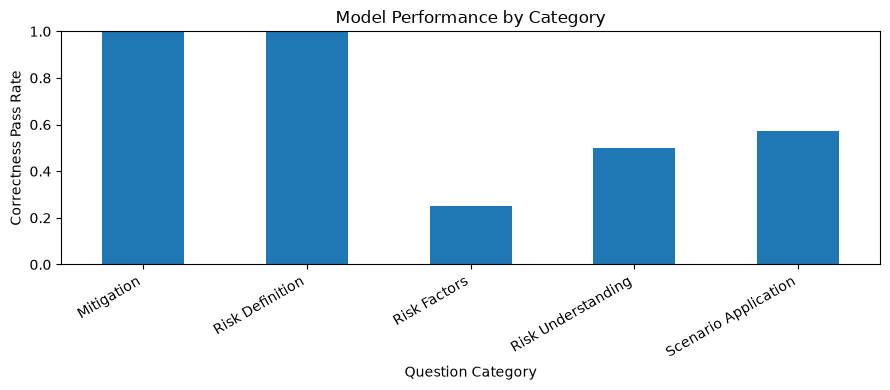

In [29]:
# TODO: performance by category and by difficulty
# The results DataFrame has no metadata, so join it from the dataset:
meta = pd.DataFrame([
    {"example_id": str(e.id), **(e.metadata or {})}
    for e in client.list_examples(dataset_name=DATASET_NAME)
])
df["example_id"] = df["example_id"].astype(str)
df = df.merge(meta, on="example_id", how="left")

# TODO: groupby category / difficulty -> pass rate; bar chart saved to OUT / "pass_rate_by_category.png"

# Performance by category
category_stats = (
    df.groupby("category")["feedback.correctness"]
    .agg(["count", "mean"])
    .reset_index()
)

category_stats.columns = ["category", "n", "pass_rate"]

print("Performance by category:")
display(category_stats)

# Performance by difficulty
difficulty_stats = (
    df.groupby("difficulty")["feedback.correctness"]
    .agg(["count", "mean"])
    .reset_index()
)

difficulty_stats.columns = ["difficulty", "n", "pass_rate"]

print("Performance by difficulty:")
display(difficulty_stats)

# Save category performance chart
ax = category_stats.plot(
    x="category",
    y="pass_rate",
    kind="bar",
    figsize=(9, 4),
    legend=False,
    ylim=(0, 1)
)

ax.set_ylabel("Correctness Pass Rate")
ax.set_xlabel("Question Category")
ax.set_title("Model Performance by Category")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUT / "pass_rate_by_category.png", dpi=150)
plt.show()

In [30]:
# Step 9: Error analysis

# Select all examples that failed the correctness evaluation
failed = df[df["feedback.correctness"] == 0].copy()

# Retrieve judge explanations from LangSmith
feedback_by_run = {
    str(feedback.run_id): feedback.comment
    for feedback in client.list_feedback(
        run_ids=failed["id"].astype(str).tolist(),
        feedback_key=["correctness"]
    )
}

# Match judge comments to failed examples
failed["judge_comment"] = (
    failed["id"].astype(str).map(feedback_by_run)
)

print(f"Failed examples: {len(failed)}")
print(
    f"Judge comments retrieved: "
    f"{failed['judge_comment'].notna().sum()} / {len(failed)}"
)

display(
    failed[
        [
            "inputs.question",
            "outputs.answer",
            "reference.answer",
            "judge_comment"
        ]
    ]
)

Failed examples: 9
Judge comments retrieved: 9 / 9


,inputs.question,outputs.answer,reference.answer,judge_comment
0,A multi-tenant RAG application retrieves priva...,This scenario illustrates the vulnerability of...,This illustrates LLM09: Vector and Embedding W...,The model's answer correctly identifies that s...
2,A company stores internal authorization rules ...,This scenario illustrates the OWASP vulnerabil...,This illustrates LLM08: Hidden Context Exposur...,The model output is incorrect. It names the OW...
6,Which three deployment-time properties make pr...,According to the OWASP GenAI LLM Top 10 (2026)...,The three properties are context-window poolin...,The model output does not match the OWASP item...
7,What are the four lifecycle phases in which se...,According to the OWASP GenAI LLM Top 10 (2026)...,"The four phases are training-time, inference-t...",The model's answer correctly identifies two of...
9,Which three axes does OWASP use to characteriz...,OWASP characterizes the anatomy of a prompt in...,"OWASP identifies three axes: delivery surface,...",The model's answer does not match the OWASP ch...
11,A developer downloads a third-party LoRA adapt...,This scenario illustrates the vulnerability of...,This illustrates LLM04: Supply Chain. Third-pa...,The response correctly identifies the nature o...
14,How does Excessive Agency differ from Improper...,Excessive Agency and Improper Output Handling ...,Excessive Agency concerns damaging actions ena...,The response correctly explains Improper Outpu...
17,Why is protecting only the final LLM response ...,Protecting only the final LLM response is insu...,Protecting only the final response is insuffic...,The answer correctly identifies some relevant ...
19,Why are traditional request-rate limits insuff...,Traditional request-rate limits are often insu...,Traditional request-rate limits are insufficie...,The response correctly notes that simple reque...


In [31]:
# Inspect three failed examples in full

for idx in [6, 7, 9]:
    row = failed.loc[idx]

    print(f"\n{'=' * 70}")
    print(f"FAILED EXAMPLE {idx}")
    print(f"{'=' * 70}")

    print("\nQUESTION:")
    print(row["inputs.question"])

    print("\nMODEL ANSWER:")
    print(row["outputs.answer"])

    print("\nREFERENCE ANSWER:")
    print(row["reference.answer"])

    print("\nJUDGE REASONING:")
    print(row["judge_comment"])


FAILED EXAMPLE 6

QUESTION:
Which three deployment-time properties make prompt injection vulnerabilities worse according to OWASP?

MODEL ANSWER:
According to the OWASP GenAI LLM Top 10 (2026), the three deployment-time properties that exacerbate prompt injection vulnerabilities are:

1. **Lack of Input Validation**: When user inputs are not properly validated or sanitized, it increases the risk of malicious prompts being executed. This can lead to unintended behavior or exposure of sensitive information.

2. **Overly Permissive Contexts**: Deployments that allow LLMs to operate in contexts with excessive permissions or capabilities can amplify the impact of prompt injection attacks. If an LLM has access to sensitive operations or data, a successful prompt injection could lead to significant security breaches.

3. **Inadequate User Authentication and Authorization**: Weak or absent authentication and authorization mechanisms can allow unauthorized users to exploit prompt injection vul

In [32]:
# Inspect the next two failed examples
for idx in [11, 14]:
    row = failed.loc[idx]

    print(f"\n{'=' * 60}")
    print(f"FAILED EXAMPLE {idx}")

    print("\nQUESTION:")
    print(row["inputs.question"])

    print("\nMODEL ANSWER:")
    print(row["outputs.answer"])

    print("\nREFERENCE ANSWER:")
    print(row["reference.answer"])

    print("\nJUDGE REASONING:")
    print(row["judge_comment"])


FAILED EXAMPLE 11

QUESTION:
A developer downloads a third-party LoRA adapter from a shared model repository. The adapter has been maliciously modified before distribution. Which OWASP vulnerability does this illustrate and why?

MODEL ANSWER:
This scenario illustrates the vulnerability of "Malicious Model Injections," which is part of the OWASP GenAI LLM Top 10. 

**Risk:** The risk here is that the developer unknowingly integrates a compromised component into their application, which can lead to various security issues, including data leakage, unauthorized access, or even the execution of harmful commands.

**Causes:** The cause of this vulnerability stems from the reliance on third-party components without adequate verification of their integrity and security. Shared model repositories may not have stringent vetting processes, allowing malicious actors to distribute modified adapters that can exploit the host application.

**Mitigations:** To mitigate this risk, developers should i

In [33]:
# Inspect the final two failed examples
for idx in [17, 19]:
    row = failed.loc[idx]

    print(f"\n{'=' * 60}")
    print(f"FAILED EXAMPLE {idx}")

    print("\nQUESTION:")
    print(row["inputs.question"])

    print("\nMODEL ANSWER:")
    print(row["outputs.answer"])

    print("\nREFERENCE ANSWER:")
    print(row["reference.answer"])

    print("\nJUDGE REASONING:")
    print(row["judge_comment"])


FAILED EXAMPLE 17

QUESTION:
Why is protecting only the final LLM response insufficient to prevent sensitive information disclosure, according to OWASP?

MODEL ANSWER:
Protecting only the final LLM response is insufficient to prevent sensitive information disclosure because sensitive data can be exposed at multiple stages throughout the interaction with the model. According to OWASP, the risks include:

1. **Input Leakage**: Users may inadvertently provide sensitive information in their prompts, which could be processed and stored by the LLM, leading to potential exposure in future interactions.

2. **Intermediate Outputs**: During the generation process, intermediate outputs or logs may contain sensitive information that could be accessed by unauthorized users or systems.

3. **Model Training Data**: If the LLM has been trained on datasets that include sensitive information, it may inadvertently generate responses that reveal this data, even if the final output seems benign.

4. **Co

In [34]:
# Manual classification of the nine failed examples
error_types = {
    0: "wrong fact",
    2: "wrong fact",
    6: "wrong fact",
    7: "wrong fact",
    9: "hallucination",
    11: "wrong fact",
    14: "wrong fact",
    17: "incomplete",
    19: "incomplete"
}

failed["error_type"] = failed.index.map(error_types)

assert failed["error_type"].notna().all()

print("Failure types:")
print(failed["error_type"].value_counts())

display(failed[["inputs.question", "error_type"]])

Failure types:
error_type
wrong fact       6
incomplete       2
hallucination    1
Name: count, dtype: int64


,inputs.question,error_type
0,A multi-tenant RAG application retrieves priva...,wrong fact
2,A company stores internal authorization rules ...,wrong fact
6,Which three deployment-time properties make pr...,wrong fact
7,What are the four lifecycle phases in which se...,wrong fact
9,Which three axes does OWASP use to characteriz...,hallucination
11,A developer downloads a third-party LoRA adapt...,wrong fact
14,How does Excessive Agency differ from Improper...,wrong fact
17,Why is protecting only the final LLM response ...,incomplete
19,Why are traditional request-rate limits insuff...,incomplete



### Key Findings

**1. Overall pass rate per evaluator**

- LLM-as-a-Judge (Correctness): 55% (11/20 passed).
- Rule-based Keyword Overlap: 95% (19/20 passed).
- The 40-percentage-point difference demonstrates that lexical similarity is not a reliable substitute for factual correctness.

**2. Easiest and hardest category**

- Highest pass rates: Mitigation (100%, 1/1) and Risk Definition (100%, 2/2).
- Lowest pass rate: Risk Factors (25%, 1/4).
- By difficulty, easy questions achieved 100%, medium 30%, and hard 66.7%.

These results are descriptive only. The dataset is small and the category sizes differ substantially.

**3. Biggest failure pattern (with one example)**

Nine answers failed the correctness evaluation:

- Wrong fact: 6
- Incomplete: 2
- Hallucination: 1

The dominant failure pattern was incorrect OWASP terminology or classification.

For example, when asked about the three deployment-time properties that worsen prompt injection, the target model listed general security issues instead of context-window pooling, memory persistence, and agentic execution.

This suggests that GPT-4o-mini can explain general security concepts but struggles with specific OWASP GenAI LLM Top 10 (2026) terminology and taxonomies.

**4. Judge mistakes or bad reference answers**

No clear judge mistakes or bad reference answers were identified during the manual review of the nine failed cases.

The negative assessments were generally consistent with the supplied reference answers. However, this does not independently establish that all reference answers are accurate.

**Statistical limitations**

The evaluation contains only 20 examples. Each example represents five percentage points of the overall pass rate.

Results should therefore be interpreted as an initial baseline rather than a statistically robust measure of general model performance.

### Step 10: `evaluation_summary.md`

**One short paragraph** (plus optional bullets/table): what you evaluated, main metrics, biggest failure pattern, limitations, one recommendation. Not a long report.

In [35]:
# Step 10: Create the evaluation summary

summary = """# Evaluation Summary

## Overview

This evaluation assessed GPT-4o-mini on 20 question-answer pairs covering all ten categories of the OWASP GenAI LLM Top 10 (2026). The target model used temperature=0 and was evaluated using two methods: an LLM-as-a-Judge correctness evaluator powered by GPT-5-mini and a deterministic keyword-overlap evaluator with a 25% threshold. The LLM Judge reported a 55% pass rate, while keyword overlap reached 95%. Manual analysis of the nine failed correctness evaluations identified six factual errors, two incomplete answers, and one hallucination. The dominant failure pattern involved incorrect OWASP terminology, classifications, and specific technical details. The small dataset, uneven category distribution, and potential limitations of automated judging restrict the generalizability of these findings. The recommended next step is to improve factual grounding using the official OWASP 2026 source material, followed by re-evaluation on a larger and more balanced dataset.

## Evaluation Metrics

| Metric | Result |
|---|---|
| Dataset size | 20 examples |
| OWASP risk categories covered | 10 |
| Target model | GPT-4o-mini |
| Judge model | GPT-5-mini |
| Correctness pass rate | 55% (11/20) |
| Keyword overlap pass rate | 95% (19/20) |
| Failed correctness evaluations | 9 |
| Wrong fact | 6 |
| Incomplete answer | 2 |
| Hallucination | 1 |

## Key Observations

- Risk Definition achieved 100% correctness (2/2).
- Risk Factors had the lowest pass rate at 25% (1/4).
- Easy questions achieved 100%, medium questions 30%, and hard questions 66.7%.
- Keyword overlap frequently accepted answers that the LLM Judge rejected.
- Manual review found no clear judge mistakes among the nine failed cases, but reference accuracy was not independently verified.

## LangSmith Experiment

https://eu.smith.langchain.com/o/30676eb8-0d5d-42d8-aa84-ca8c16dce2c5/datasets/f36ce8bb-1f79-441f-9c59-b78ca1a6929d/compare?selectedSessions=68548a5f-d128-4510-859b-3b6574eca64c
"""

Path("evaluation_summary.md").write_text(
    summary,
    encoding="utf-8"
)

print("Evaluation summary saved successfully!")
print(Path("evaluation_summary.md").resolve())

Evaluation summary saved successfully!
C:\Users\maxke\Desktop\Ironhack\Coursework\Week7\Day34 - Model Evaluation and LangSmith\lab-langsmith\evaluation_summary.md


---
## Optional Part 1: Custom evaluator (60–90 min)
### Step 11: Design it

Pick **one** dimension beyond correctness that matters for your domain: tone, completeness, groundedness in the context, safety / policy compliance, format…

 **Hints:**
- Use the 4-part judge prompt anatomy from notebook 01, §3: task, what you're given, criteria, reasoning steps + output format.
- Your prompt's `{variables}` must match the keyword arguments you pass (`inputs`, `outputs`, `reference_outputs`, or your own like `context`).
- Prebuilt prompts you can adapt: `RAG_GROUNDEDNESS_PROMPT`, `ANSWER_RELEVANCE_PROMPT`, `CONCISENESS_PROMPT`, `TOXICITY_PROMPT` (`print()` one to see how it's written).
- For a 1–5 scale instead of True/False: `create_llm_as_judge(..., continuous=True)` gives a 0–1 score, or `choices=[1, 2, 3, 4, 5]`.

In [ ]:
CUSTOM_PROMPT = '''
TODO: your judge prompt with {inputs}, {outputs} (and {reference_outputs} if needed)
'''

custom_judge = ...

def custom_evaluator(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    ...

# TODO: test on 2-3 hand-made cases (one good, one bad, one borderline)
...

### Step 12: Run it next to correctness

In [ ]:
# TODO: new experiment with correctness + custom evaluator, then compare the two scores per example
results_custom = ...
...
# Which examples are CORRECT but score badly on your custom dimension (or the other way round)?
...

### Step 13:  Document your custom evaluator
- What it measures and why it matters in my domain:
- Scoring scale and criteria:
- Where it disagreed with correctness, and what that revealed:

---
## Optional Part 2: Cost & performance (60–90 min)
### Step 14: A/B comparison

 **Hints (§4 of `02_langsmith(1).ipynb`):**
- Same dataset, same evaluators, **only one thing changes** (the model, or the temperature, or the prompt).
- To get token usage, also return it from the target: `{"answer": ..., "prompt_tokens": r.usage.prompt_tokens, "completion_tokens": r.usage.completion_tokens}`.
- Latency: look for an `execution_time` column in `results.to_pandas()`.
- Fill `PRICES` from the **OpenAI pricing page** (USD per 1M tokens). Write down the date you checked it.

In [ ]:
CONFIGS = {
    # experiment name: model
    "config-a": "gpt-4o-mini",
    "config-b": ...,
    # "config-c": ...,
}

PRICES = {   # USD per 1M tokens, from the OpenAI pricing page (checked on: ...)
    "gpt-4o-mini": {"input": ..., "output": ...},
    # ...
}

def make_target(model):
    @traceable(name=f"lab-target-{model}")
    def _target(inputs: dict) -> dict:
        # TODO: same as your target, but with `model` and token usage in the returned dict
        ...
    return _target

# TODO: run one experiment per config and keep the results
ab_results = {}
...

### Step 15: Cost vs performance

In [ ]:
# TODO: one row per config: pass rate, avg latency, total cost, cost per example, cost per CORRECT answer
# cost = prompt_tokens / 1e6 * price_in + completion_tokens / 1e6 * price_out
...
# TODO: scatter plot: x = cost per example, y = pass rate, one labelled point per config
...
plt.savefig(OUT / "cost_vs_performance.png", dpi=120)
plt.show()

 **Before you recommend, think:**
- Is the gap between models bigger than **one or two examples**? With ~20 examples it may be luck (W7/D5).
- Which pass rate is **good enough** for this use case? A cheaper model that meets that bar wins.

### Step 16: `optimization_summary.md`

In [ ]:
# TODO: one short paragraph: best cost/performance trade-off, and when you would pick each config
opt = '''# Optimization summary

TODO: best trade-off + when to pick each configuration.

| Config | Model | Pass rate | Cost / correct answer | Avg latency |
|---|---|---|---|---|
| ... | ... | ... | ... | ... |
'''
Path("optimization_summary.md").write_text(opt, encoding="utf-8")

---
## Reflection (optional, recommended)
1. What surprised you when you read the failed traces?
2. Did you trust your LLM judge? How did you check it?
3. What would you change in your dataset for a `-v2`?

## Submission checklist
- [ ] GitHub repo with **only** this lab, and a `README.md` (domain + dataset, approach, how to run, LangSmith links, file map)
- [ ] `lab_proof.md` as the **entry point**: code/workflow, one run with its input, the evidence it produced (trace / screenshot), the final output, and one failure or limitation you hit
- [ ] `evaluation_summary.md` at the repo root (one paragraph + optional table)
- [ ] (Optional) `optimization_summary.md` at the repo root
- [ ] Notebook runs top to bottom without errors; descriptive file names (no `lab.ipynb`, `final_v2.py`)
- [ ] `outputs/`: results CSV(s), charts, and LangSmith screenshots (dataset, experiment, one trace)
- [ ] **No API keys** in the repo: `.env` is in `.gitignore`